# Chapter 8 — Variational autoencoders

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mengrenman/artificial_intelligence_engines/blob/main/notebooks/08_vae.ipynb)

Companion notebook for Stone, *Artificial Intelligence Engines* (2020), Chapter 8.
The encoder maps $x_t$ to the mean $\mu_t$ and (log) variance $\log\sigma^2_t$ of a
diagonal Gaussian $q(z|x_t)=\mathcal N(\mu_t,\Sigma_t)$ over a $J$-dimensional latent space;
the decoder maps a sample $z$ back to a reconstruction $x'$. Dropping the constant $c$, the
objective for one training vector is (Eq 8.37)
$$L_t = \underbrace{-\frac{1}{2N_z}\sum_{i=1}^{N_z}|x_t-x'_{it}|^2}_{L^{\rm dec}_t\ \text{(Eq 8.35)}}
\;+\;\underbrace{\frac12\sum_{j=1}^{J}\left(1+\log\sigma^2_{jt}-\sigma^2_{jt}-\mu^2_{jt}\right)}_{L^{\rm enc}_t\ \text{(Eq 8.36)}},$$
where $N_z$ is the number of $z$ samples per input. $L^{\rm enc}_t$ is minus the KL divergence
between $q(z|x_t)$ and the prior $p(z)=\mathcal N(0,I)$. Samples use the **reparametrisation
trick** $z=\mu+\eta\sigma$, $\eta\sim\mathcal N(0,I)$, so gradients pass through $\mu$ and $\sigma$.
We maximise $L$ (equivalently minimise $-L$). Code: `scripts/vae.py`.

In [1]:
# Colab setup: install the companion package (does nothing when run locally).
try:
    import google.colab  # noqa: F401
    %pip install -q git+https://github.com/mengrenman/artificial_intelligence_engines
except ImportError:
    pass

In [2]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from aie.data import digits
from aie.plotting import show_image_grid
from scripts.vae import VAE

## Data and model
We use `aie.data.digits(max_shift=0)`: centred 12×12 digits with pixel noise. (With the default
random shifts of ±2 pixels most of the pixel variance is due to *position*, and a 2-D latent space
spends its capacity on encoding the shift rather than the digit identity.)

Eq 8.35 assumes a Gaussian decoder with variance $\sigma_x^2=1$. `VAE(sigma_x2=...)` generalises
this to $L^{\rm dec}_t=-\frac{1}{2\sigma_x^2N_z}\sum_i|x_t-x'_{it}|^2$; we use $\sigma_x^2=0.1$ (a
sharper likelihood, i.e. reconstruction weighted 10× relative to the KL term) and compare with the
book's $\sigma_x^2=1$ at the end.

Architecture: 144-pixel digits; encoder 144-128-64-(2+2), decoder 2-64-128-144 with tanh hidden units and a
sigmoid output layer. The final encoder layer outputs $[\mu, \log\sigma^2]$, so $\sigma^2=e^{\log\sigma^2}$
is positive by construction.

In [3]:
X_img, y = digits(n_per_class=100, max_shift=0, seed=0)
X = X_img.reshape(len(X_img), -1)
vae = VAE(144, n_latent=2, hidden=(128, 64), activation='tanh', seed=0, sigma_x2=0.1)
vae.fit(X, n_epochs=300, lr=1e-3, batch_size=32, n_z=1)
print('final -L = %.3f  (recon %.3f, KL %.3f)' % (vae.history['loss'][-1],
      vae.history['recon'][-1], vae.history['kl'][-1]))

final -L = 6.041  (recon 2.722, KL 3.319)


## Loss curves
Reconstruction cost $-L^{\rm dec}$ and regularisation cost $-L^{\rm enc}=\mathrm{KL}(q\,\|\,p)$ plotted
separately. The KL term rises early on as the encoder starts to use the latent space,
trading off against a falling reconstruction error.

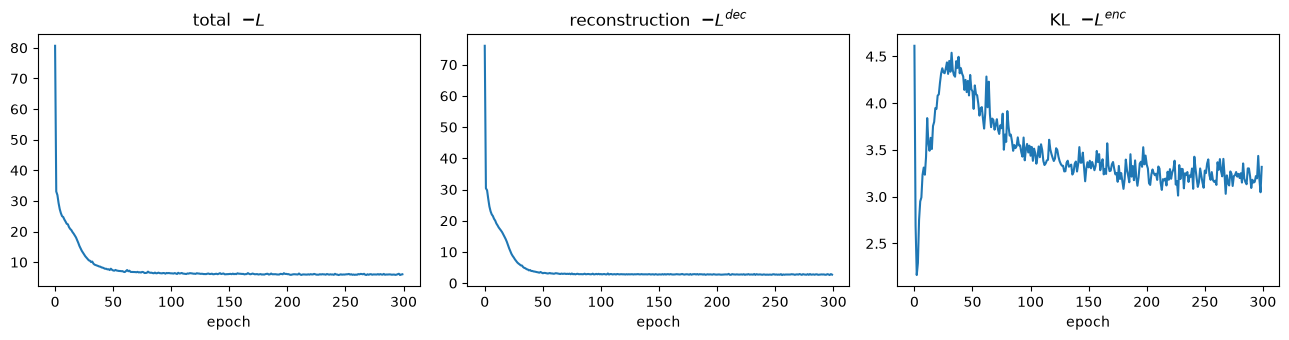

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, k, t in zip(axes, ['loss', 'recon', 'kl'], ['total  $-L$', 'reconstruction  $-L^{dec}$', 'KL  $-L^{enc}$']):
    ax.plot(vae.history[k]); ax.set_title(t); ax.set_xlabel('epoch')
fig.tight_layout()

**Reconstructions** (top: data; bottom: decoder output for $z=\mu$).

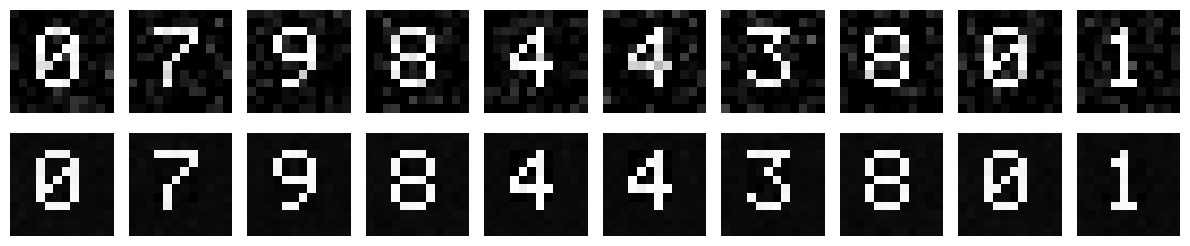

In [5]:
idx = np.arange(10)
show_image_grid(list(X_img[idx]) + list(vae.reconstruct(X[idx]).reshape(-1, 12, 12)),
                cols=10, figsize=(12, 2.8));

## Latent space
Encoder means $\mu$ for every image, coloured by digit label.

mean sigma: [0.22916707 0.22551676]


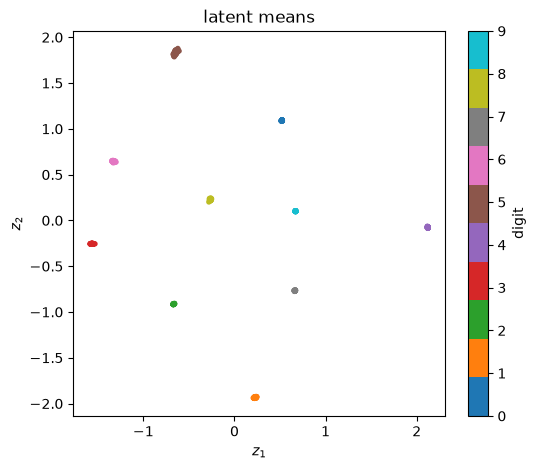

In [6]:
mu, logvar = vae.encode(X)
plt.figure(figsize=(6, 5))
sc = plt.scatter(mu[:, 0], mu[:, 1], c=y, cmap='tab10', s=8)
plt.colorbar(sc, ticks=range(10), label='digit'); plt.xlabel('$z_1$'); plt.ylabel('$z_2$')
plt.title('latent means'); print('mean sigma:', np.exp(0.5 * logvar).mean(axis=0))

**Decoded grid.** Because the prior is $\mathcal N(0,I)$, the latent plane is covered by a grid
of $z$ values at the quantiles $\Phi^{-1}(0.05\dots0.95)$ of a standard normal, each decoded to an image.

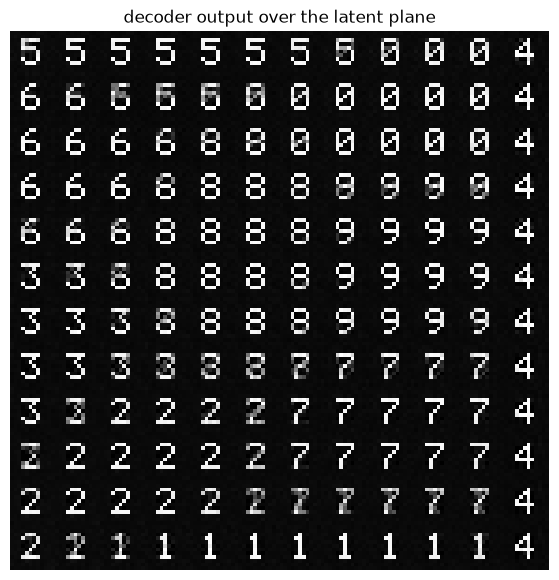

In [7]:
from scipy.stats import norm
n = 12
grid = norm.ppf(np.linspace(0.05, 0.95, n))
Z = np.array([[z1, z2] for z2 in grid[::-1] for z1 in grid])
imgs = vae.decode(Z).reshape(n, n, 12, 12)
canvas = imgs.transpose(0, 2, 1, 3).reshape(n * 12, n * 12)
plt.figure(figsize=(7, 7)); plt.imshow(canvas, cmap='gray', vmin=0, vmax=1)
plt.axis('off'); plt.title('decoder output over the latent plane');

## Random samples from the prior
$z\sim\mathcal N(0,I)$, decoded.

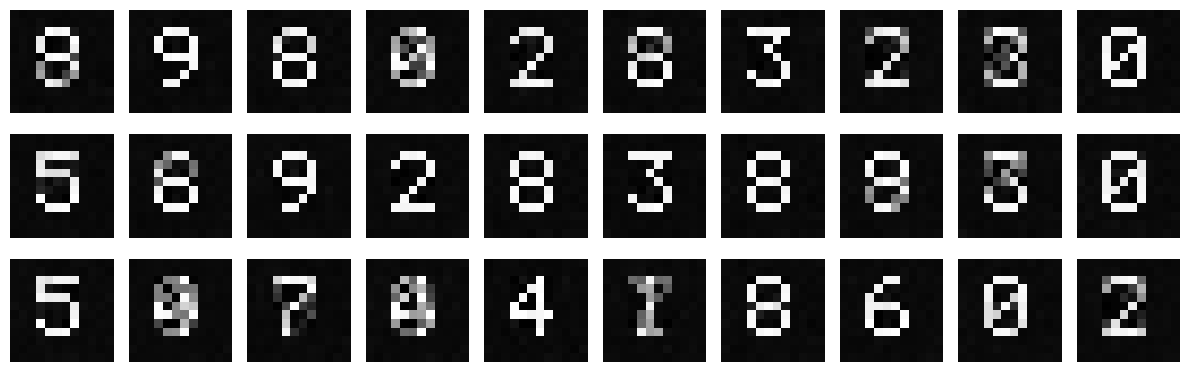

In [8]:
samples = vae.sample(30, rng=np.random.default_rng(0))
show_image_grid(list(samples.reshape(-1, 12, 12)), cols=10, figsize=(12, 4));

## Effect of the decoder variance $\sigma_x^2$
With the book's $\sigma_x^2=1$ the reconstruction term is weak relative to the KL term, so the
encoder keeps $q(z|x)$ close to the prior: the KL cost is small and the digit classes overlap more
(in the limit this is *posterior collapse*, $q(z|x)=p(z)$). Note that $-L^{\rm dec}$ is scaled by $1/\sigma_x^2$, so we compare the raw $\frac12|x-x'|^2$.

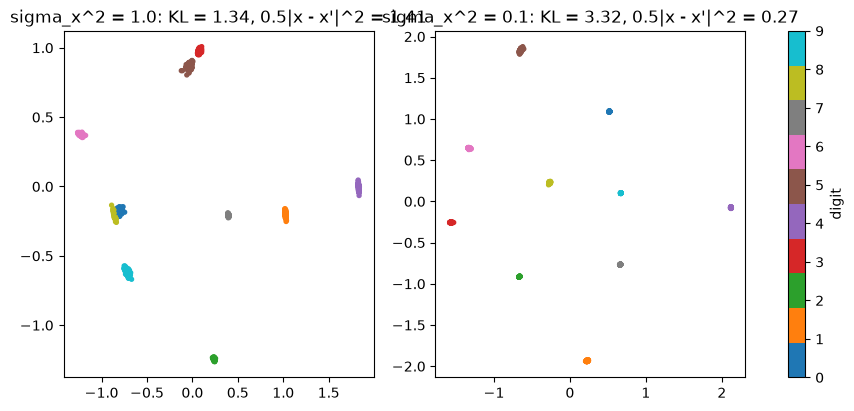

In [9]:
vae1 = VAE(144, n_latent=2, hidden=(128, 64), activation='tanh', seed=0, sigma_x2=1.0)
vae1.fit(X, n_epochs=300, lr=1e-3, batch_size=32)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, model, s2 in zip(axes, [vae1, vae], [1.0, 0.1]):
    m, _ = model.encode(X)
    sc = ax.scatter(m[:, 0], m[:, 1], c=y, cmap='tab10', s=8)
    sq = model.history['recon'][-1] * s2
    ax.set_title(f"sigma_x^2 = {s2}: KL = {model.history['kl'][-1]:.2f}, 0.5|x - x'|^2 = {sq:.2f}")
fig.colorbar(sc, ax=axes, ticks=range(10), label='digit');

## Summary
The VAE learns a smooth 2-D latent space organised by digit class: nearby latent points decode
to similar images, and samples from the prior produce plausible digits. This is possible because
the KL term (Eq 8.36) keeps $q(z|x)$ close to $\mathcal N(0,I)$, while the reparametrisation trick
lets backprop train the encoder through the sampling step.